# Phân tích & học máy trên giá rau quả trong nước (thitruongnongsan.gov.vn)

**Dữ liệu:** `ttns.v_price_monthly` trong ClickHouse - giá trung vị theo tháng của từng mặt hàng × tỉnh × loại giá,
04/2021 → 12/2025, đã làm sạch bởi DAG `ttns_price_pipeline`. Chỉ dùng đơn vị **VNĐ/kg** (95% dữ liệu).

**Nội dung**
1. Tổng quan dữ liệu
2. Mùa vụ: chỉ số mùa vụ theo tháng, phân cụm mặt hàng (KMeans)
3. Dự báo giá: so sánh 7 phương pháp, tầm dự báo 1-6 tháng, khoảng giá (conformal), độ quan trọng feature,
   dự đoán chiều giá
4. Phát hiện giá bất thường (robust z-score)
5. Chênh lệch giá bán lẻ - thu mua và độ trễ truyền dẫn

Chạy lại: `jupytext --to notebook phan_tich_gia_nong_san.py && jupyter nbconvert --execute --to notebook --inplace phan_tich_gia_nong_san.ipynb`
(lần đầu đọc ClickHouse ở localhost:8123 rồi lưu `data/ttns_v_price_monthly.csv`; các lần sau đọc file CSV).

In [1]:
import os
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, f1_score, silhouette_score
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, AutoTheta

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

DATA_DIR, FIG_DIR, OUT_DIR = Path("data"), Path("figures"), Path("outputs")
for d in (DATA_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(exist_ok=True)

# ---- giao diện biểu đồ (bảng màu tham chiếu của skill dataviz, chế độ sáng, đã chạy validator) ----
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # slot 1-4 theo đúng thứ tự
CRITICAL = "#d03b3b"
CAP_COLOR = {"Bán lẻ": S1, "Thu mua": S2, "Bán buôn": S3}       # màu đi theo thực thể, không theo thứ hạng
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#184f95", "#5598e7", "#f0efec", "#e66767", "#a32626"])
SEQ_BLUE = LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.labelcolor": INK2, "text.color": INK, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "lines.linewidth": 2, "legend.frameon": False,
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def pct(x):
    return f"{x:.1%}"

g:\Study\KhoDL\data\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dữ liệu

In [2]:
CSV = DATA_DIR / "ttns_v_price_monthly.csv"
if not CSV.exists():
    sql = "SELECT * FROM ttns.v_price_monthly ORDER BY month FORMAT CSVWithNames"
    r = requests.post(os.getenv("CLICKHOUSE_URL", "http://localhost:8123"), data=sql.encode(),
                      auth=("default", os.getenv("CLICKHOUSE_PASSWORD", "mypassword")), timeout=120)
    r.raise_for_status()
    CSV.write_text(r.text, encoding="utf-8")
raw = pd.read_csv(CSV, parse_dates=["month"])
print(f"Toàn bộ view: {len(raw):,} dòng; đơn vị: {raw['don_vi_tinh'].value_counts().to_dict()}")

KEY = ["nhom_san_pham", "san_pham", "mat_hang", "tinh_cu", "loai_gia", "don_vi_tinh"]
df = raw[raw["don_vi_tinh"] == "VNĐ/kg"].copy()
df["sid"] = df.groupby(KEY, sort=True).ngroup()
df["y"] = np.log(df["median_price"])

lengths = df.groupby("sid")["month"].agg(["count", "min", "max"])
overview = pd.Series({
    "Khoảng thời gian": f"{df['month'].min():%m/%Y} → {df['month'].max():%m/%Y}",
    "Số dòng (mặt hàng × tỉnh × tháng × loại giá)": f"{len(df):,}",
    "Số lần báo giá gốc (tổng n_obs)": f"{df['n_obs'].sum():,}",
    "Sản phẩm / mặt hàng / tỉnh": f"{df['san_pham'].nunique()} / {df['mat_hang'].nunique()} / {df['tinh_cu'].nunique()}",
    "Số chuỗi giá": f"{len(lengths)}",
    "Chuỗi ≥ 12 / ≥ 24 / ≥ 36 tháng": f"{(lengths['count'] >= 12).sum()} / {(lengths['count'] >= 24).sum()} / {(lengths['count'] >= 36).sum()}",
    "Độ dài chuỗi trung bình (tháng)": f"{lengths['count'].mean():.1f}",
})
overview.to_frame("giá trị")

Toàn bộ view: 7,337 dòng; đơn vị: {'VNĐ/kg': 6925, 'VNĐ/chục quả': 177, 'VNĐ/mớ': 128, 'VNĐ/quả': 87, 'VNĐ/củ': 17, 'VNĐ/cây': 3}


,giá trị
Khoảng thời gian,04/2021 → 12/2025
Số dòng (mặt hàng × tỉnh × tháng × loại giá),"6,925"
Số lần báo giá gốc (tổng n_obs),"38,341"
Sản phẩm / mặt hàng / tỉnh,73 / 188 / 14
Số chuỗi giá,429
Chuỗi ≥ 12 / ≥ 24 / ≥ 36 tháng,210 / 126 / 49
Độ dài chuỗi trung bình (tháng),16.1


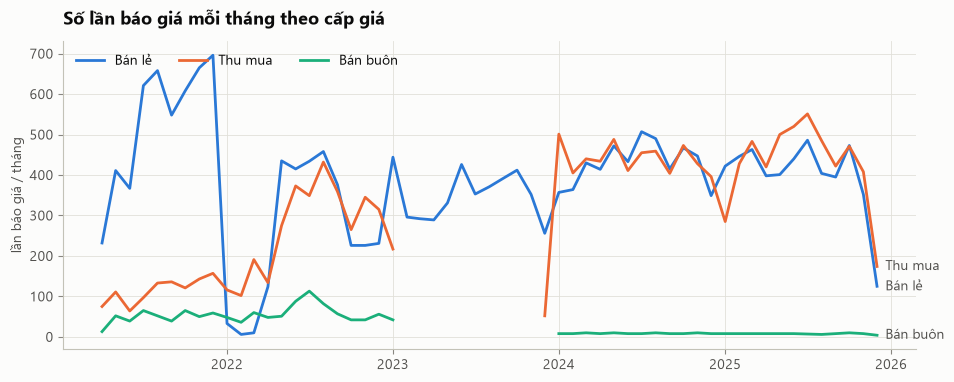

In [3]:
obs = df.groupby(["month", "cap_gia"])["n_obs"].sum().unstack().reindex(columns=list(CAP_COLOR))
fig, ax = plt.subplots(figsize=(11, 4))
for cap in obs.columns:
    s = obs[cap]
    ax.plot(s.index, s.values, color=CAP_COLOR[cap], label=cap)
    last = s.dropna()
    ax.annotate(cap, (last.index[-1], last.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color=INK2, va="center", fontsize=10)
ax.set_title("Số lần báo giá mỗi tháng theo cấp giá")
ax.set_ylabel("lần báo giá / tháng")
ax.legend(loc="upper left", ncols=3)
save(fig, "01_so_lan_bao_gia")

,so_diem,thay_doi_trung_vi,p90,tang_gt_2pct,giam_gt_2pct
cap_gia,,,,,
Bán lẻ,2651,5.9%,33.3%,27.5%,26.1%
Thu mua,3087,7.1%,33.3%,36.6%,32.8%
Bán buôn,345,6.1%,29.5%,28.7%,34.2%


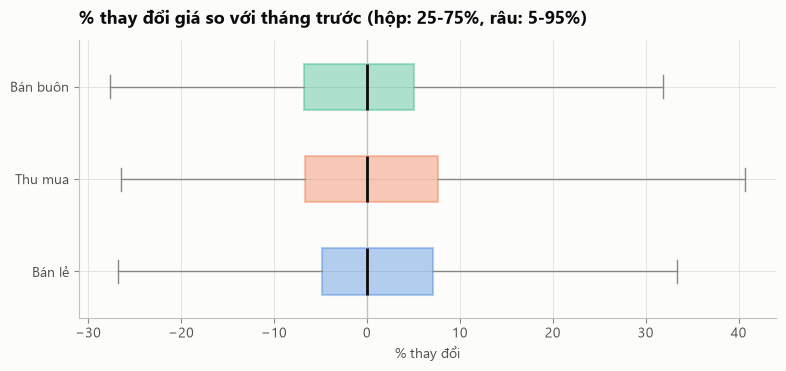

In [4]:
df = df.sort_values(["sid", "month"])
prev = df.groupby("sid")[["month", "y"]].shift(1)
consec = (df["month"] - pd.DateOffset(months=1)) == prev["month"]
df["ret1"] = np.where(consec, df["y"] - prev["y"], np.nan)

vol = df.dropna(subset=["ret1"]).groupby("cap_gia")["ret1"].agg(
    so_diem="size",
    thay_doi_trung_vi=lambda r: np.median(np.abs(np.expm1(r))),
    p90=lambda r: np.quantile(np.abs(np.expm1(r)), 0.9),
    tang_gt_2pct=lambda r: (r > np.log1p(0.02)).mean(),
    giam_gt_2pct=lambda r: (r < np.log1p(-0.02)).mean(),
).reindex(list(CAP_COLOR))
display(vol.style.format({c: "{:.1%}" for c in vol.columns if c != "so_diem"}))

fig, ax = plt.subplots(figsize=(9, 3.6))
data = [np.expm1(df.loc[df["cap_gia"] == c, "ret1"].dropna()) * 100 for c in CAP_COLOR]
bp = ax.boxplot(data, vert=False, whis=(5, 95), showfliers=False, widths=0.5, patch_artist=True,
                tick_labels=list(CAP_COLOR), medianprops=dict(color=INK, linewidth=2))
for patch, c in zip(bp["boxes"], CAP_COLOR.values()):
    patch.set(facecolor=c, alpha=0.35, edgecolor=c, linewidth=1.5)
for part in ("whiskers", "caps"):
    for line in bp[part]:
        line.set(color=MUTED, linewidth=1)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_title("% thay đổi giá so với tháng trước (hộp: 25-75%, râu: 5-95%)")
ax.set_xlabel("% thay đổi")
save(fig, "02_bien_dong_thang")

## 2. Mùa vụ
Chỉ số mùa vụ của một chuỗi = trung bình (theo các năm) của `log giá tháng − log giá trung bình của năm đó`
→ tách mùa vụ khỏi xu hướng tăng giá giữa các năm. Chỉ dùng năm có ≥ 6 tháng dữ liệu.

Chuỗi đủ điều kiện tính mùa vụ (≥ 10/12 tháng có số liệu): 169


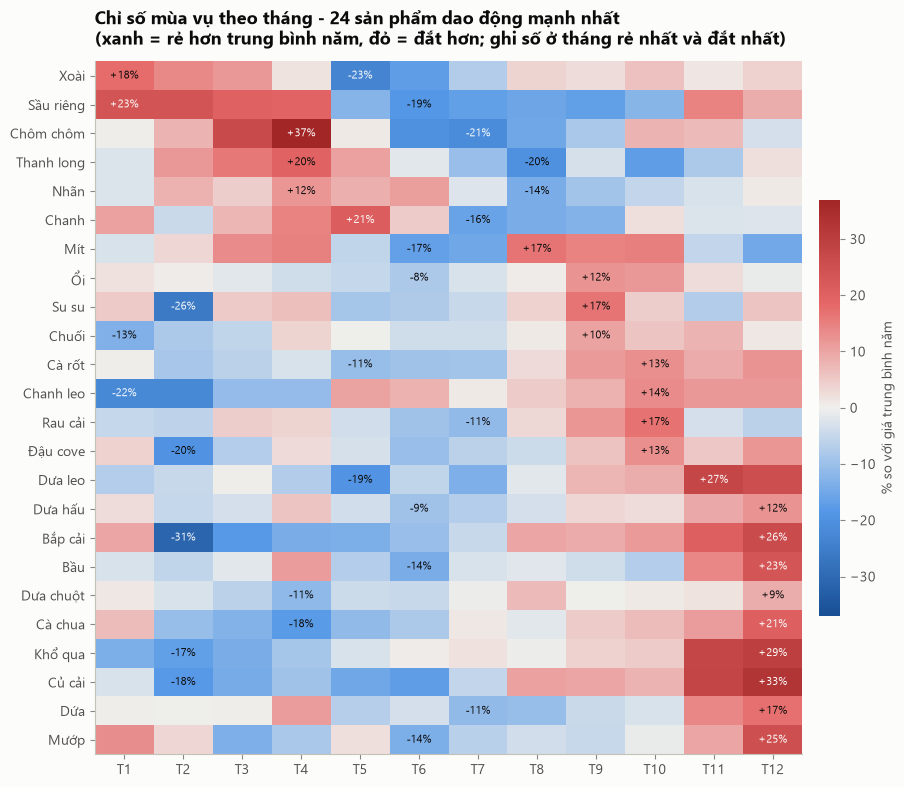

,tháng rẻ nhất,rẻ hơn TB,tháng đắt nhất,đắt hơn TB,biên độ (điểm %)
san_pham,,,,,
Chôm chôm,T7,-21.0,T4,37.0,58.0
Bắp cải,T2,-31.0,T12,26.0,57.0
Củ cải,T2,-18.0,T12,33.0,51.0
Dưa leo,T5,-19.0,T11,27.0,47.0
Khổ qua,T2,-17.0,T12,29.0,46.0
Sầu riêng,T6,-19.0,T1,23.0,42.0
Su su,T2,-26.0,T9,17.0,42.0
Xoài,T5,-23.0,T1,18.0,41.0
Thanh long,T8,-20.0,T4,20.0,40.0


In [5]:
df["year"] = df["month"].dt.year
df["mo"] = df["month"].dt.month
ycount = df.groupby(["sid", "year"])["y"].transform("size")
dd = df[ycount >= 6].copy()
dd["dev"] = dd["y"] - dd.groupby(["sid", "year"])["y"].transform("mean")
prof = dd.groupby(["sid", "mo"])["dev"].mean().unstack()          # chuỗi × 12 tháng
eligible = prof.notna().sum(axis=1) >= 10
prof = prof[eligible]
meta = df.drop_duplicates("sid").set_index("sid")[KEY + ["cap_gia", "tinh_moi"]]
print(f"Chuỗi đủ điều kiện tính mùa vụ (≥ 10/12 tháng có số liệu): {len(prof)}")

# heatmap theo sản phẩm: trung bình chỉ số các chuỗi của sản phẩm
sp_prof = prof.join(meta["san_pham"]).groupby("san_pham").mean()
sp_n = prof.join(meta["san_pham"]).groupby("san_pham").size()
sp_prof = sp_prof[sp_n >= 2]
top = sp_prof.loc[(sp_prof.max(axis=1) - sp_prof.min(axis=1)).sort_values(ascending=False).index[:24]]
top = top.loc[top.idxmax(axis=1).sort_values().index]               # sắp theo tháng đắt nhất
heat = np.expm1(top) * 100

fig, ax = plt.subplots(figsize=(11, 9))
lim = np.nanmax(np.abs(heat.values))
im = ax.imshow(heat.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(12), [f"T{m}" for m in range(1, 13)])
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
for i in range(heat.shape[0]):
    j_max, j_min = np.nanargmax(heat.values[i]), np.nanargmin(heat.values[i])
    for j, txt in ((j_max, "đắt"), (j_min, "rẻ")):
        ax.text(j, i, f"{heat.values[i, j]:+.0f}%", ha="center", va="center", fontsize=8,
                color="white" if abs(heat.values[i, j]) > lim * 0.55 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cb.set_label("% so với giá trung bình năm", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Chỉ số mùa vụ theo tháng - 24 sản phẩm dao động mạnh nhất\n(xanh = rẻ hơn trung bình năm, đỏ = đắt hơn; ghi số ở tháng rẻ nhất và đắt nhất)")
save(fig, "03_heatmap_mua_vu")

season_tbl = pd.DataFrame({
    "tháng rẻ nhất": "T" + heat.idxmin(axis=1).astype(str), "rẻ hơn TB": heat.min(axis=1).round(0),
    "tháng đắt nhất": "T" + heat.idxmax(axis=1).astype(str), "đắt hơn TB": heat.max(axis=1).round(0),
    "biên độ (điểm %)": (heat.max(axis=1) - heat.min(axis=1)).round(0),
}).sort_values("biên độ (điểm %)", ascending=False)
season_tbl.to_csv(OUT_DIR / "mua_vu_san_pham.csv", encoding="utf-8-sig")
season_tbl.head(15)

### Phân cụm chuỗi theo hình dạng mùa vụ (KMeans)
Mỗi chuỗi = vector 12 chỉ số mùa vụ (tháng thiếu = 0). Chọn số cụm k ∈ [3, 6] theo silhouette.

silhouette: {3: 0.2, 4: 0.207, 5: 0.2, 6: 0.176} → chọn k = 4


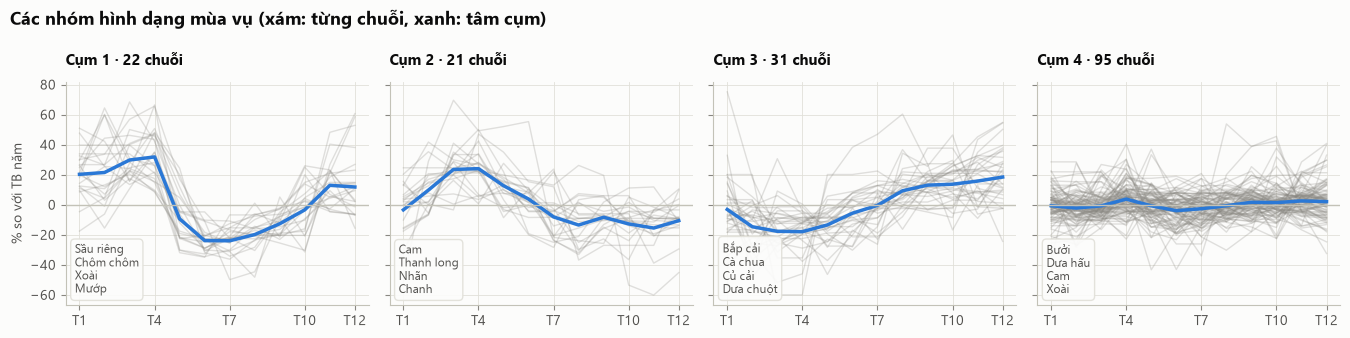

,số chuỗi,tháng đắt nhất,tháng rẻ nhất,biên độ %,sản phẩm tiêu biểu
cụm,,,,,
1,22,T4,T7,55.8,"Sầu riêng, Chôm chôm, Xoài, Mướp, Thanh long, ..."
2,21,T4,T11,39.5,"Cam, Thanh long, Nhãn, Chanh, Chôm chôm, Rau cải"
3,31,T12,T4,36.4,"Bắp cải, Cà chua, Củ cải, Dưa chuột, Khổ qua, ..."
4,95,T4,T6,7.7,"Bưởi, Dưa hấu, Cam, Xoài, Nhãn, Quả bí"


In [6]:
X = prof.fillna(0).values
scores = {}
for k in range(3, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    scores[k] = silhouette_score(X, km.labels_)
best_k = max(scores, key=scores.get)
print("silhouette:", {k: round(v, 3) for k, v in scores.items()}, "→ chọn k =", best_k)
km = KMeans(n_clusters=best_k, n_init=20, random_state=0).fit(X)
clus = pd.Series(km.labels_, index=prof.index, name="cluster")
# đánh số cụm theo tháng đỉnh để dễ đọc
peak = {c: int(np.argmax(km.cluster_centers_[c])) + 1 for c in range(best_k)}
amp = {c: np.ptp(km.cluster_centers_[c]) for c in range(best_k)}
order = sorted(range(best_k), key=lambda c: (amp[c] < 0.08, peak[c]))
rename = {c: i + 1 for i, c in enumerate(order)}
clus = clus.map(rename)
centers = {rename[c]: km.cluster_centers_[c] for c in range(best_k)}

fig, axes = plt.subplots(1, best_k, figsize=(3.4 * best_k, 3.4), sharey=True)
months = np.arange(1, 13)
summary_rows = []
for ax, cid in zip(axes, sorted(centers)):
    members = clus[clus == cid].index
    for sid in members:
        ax.plot(months, np.expm1(prof.loc[sid].values) * 100, color=MUTED, alpha=0.25, linewidth=1)
    c = np.expm1(centers[cid]) * 100
    ax.plot(months, c, color=S1, linewidth=2.5)
    ax.axhline(0, color=AXIS, linewidth=1)
    top_sp = meta.loc[members, "san_pham"].value_counts().index[:4].tolist()
    ax.set_title(f"Cụm {cid} · {len(members)} chuỗi", fontsize=11)
    ax.text(0.03, 0.04, "\n".join(top_sp), transform=ax.transAxes, fontsize=8.5, color=INK2, va="bottom",
            bbox=dict(boxstyle="round,pad=0.35", facecolor=SURF, edgecolor=GRID, alpha=0.92))
    ax.set_xticks([1, 4, 7, 10, 12], ["T1", "T4", "T7", "T10", "T12"])
    summary_rows.append({"cụm": cid, "số chuỗi": len(members), "tháng đắt nhất": f"T{int(np.argmax(c)) + 1}",
                         "tháng rẻ nhất": f"T{int(np.argmin(c)) + 1}", "biên độ %": round(np.ptp(c), 1),
                         "sản phẩm tiêu biểu": ", ".join(meta.loc[members, "san_pham"].value_counts().index[:6])})
axes[0].set_ylabel("% so với TB năm")
fig.suptitle("Các nhóm hình dạng mùa vụ (xám: từng chuỗi, xanh: tâm cụm)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "04_cum_mua_vu")
cluster_tbl = pd.DataFrame(summary_rows).set_index("cụm")
cluster_tbl.to_csv(OUT_DIR / "cum_mua_vu.csv", encoding="utf-8-sig")
cluster_tbl

## 3. Dự báo giá
**Thiết kế backtest (rolling-origin):** tại mỗi tháng gốc *o*, chỉ dùng dữ liệu đến *o* để dự báo *o+1 … o+6*.
- Tập hiệu chỉnh (để tính khoảng giá): gốc 12/2023 → 11/2024
- Tập kiểm tra: gốc 12/2024 → 11/2025 (12 gốc)
- Sai số tính trên giá thật (VNĐ), chỉ ở các tháng có số liệu thật.

**Các phương pháp**
| Tên | Mô tả |
|---|---|
| naive | giá tháng tới = giá tháng gốc |
| seasonal naive | = giá cùng tháng năm trước |
| TB 3 tháng | trung bình 3 tháng gần nhất |
| AutoETS, AutoTheta | mô hình từng chuỗi (statsforecast, season_length = 12), chuỗi có ≥ 24 tháng; tháng trống được nội suy khi train |
| LightGBM | 1 mô hình chung cho mọi chuỗi và mọi tầm h, dự báo `log giá(o+h) − log giá(o)` |
| Ensemble | trung bình (log) của naive, AutoETS, LightGBM |

In [7]:
H = 6
grid_parts = []
for sid, g in df.groupby("sid"):
    idx = pd.date_range(g["month"].min(), g["month"].max(), freq="MS")
    grid_parts.append(g.set_index("month")[["y", "n_obs"]].reindex(idx).rename_axis("month").reset_index().assign(sid=sid))
grid = pd.concat(grid_parts, ignore_index=True).join(meta, on="sid")
grid = grid.sort_values(["sid", "month"]).reset_index(drop=True)
gy = grid.groupby("sid")["y"]

# feature tại tháng gốc t (chỉ dùng thông tin ≤ t)
grid["lag0"] = grid["y"]
for k in (1, 2, 3, 6, 12):
    grid[f"d{k}"] = gy.shift(k) - grid["y"]                       # mức giá k tháng trước so với hiện tại
grid["ret1"] = grid["y"] - gy.shift(1)
grid["vol6"] = grid.groupby("sid")["ret1"].transform(lambda s: s.rolling(6, min_periods=3).std())
grid["age"] = grid.groupby("sid").cumcount()
grid["n_obs0"] = grid["n_obs"]
grid["mkt_ret1"] = grid.groupby(["san_pham", "month"])["ret1"].transform("mean")   # cùng sản phẩm, mọi nơi
CATS = ["nhom_san_pham", "san_pham", "tinh_moi", "cap_gia"]

rows = []
for h in range(1, H + 1):
    t = grid[["sid", "month", "y", "lag0", "d1", "d2", "d3", "d6", "d12", "ret1", "vol6", "age", "n_obs0",
              "mkt_ret1"] + CATS].copy()
    t["h"] = h
    t["target_month"] = t["month"] + pd.DateOffset(months=h)
    t["y_target"] = gy.shift(-h)
    t["season_h"] = gy.shift(12 - h) - gy.shift(12)                 # năm trước: giá đổi bao nhiêu sau h tháng
    t["snaive"] = gy.shift(12 - h)                                   # giá cùng tháng năm trước
    t["ma3"] = grid.groupby("sid")["y"].transform(lambda s: s.rolling(3, min_periods=3).mean())
    tm = t["target_month"].dt.month
    t["tm_sin"], t["tm_cos"] = np.sin(2 * np.pi * tm / 12), np.cos(2 * np.pi * tm / 12)
    rows.append(t)
panel = pd.concat(rows, ignore_index=True)
panel = panel[panel["lag0"].notna()].copy()                          # cần giá tại tháng gốc
panel["target"] = panel["y_target"] - panel["lag0"]
for c in CATS:
    panel[c] = panel[c].astype("category")
FEATS = ["h", "d1", "d2", "d3", "d6", "d12", "ret1", "vol6", "age", "n_obs0", "mkt_ret1", "season_h",
         "tm_sin", "tm_cos"] + CATS

CAL_ORIGINS = pd.date_range("2023-12-01", "2024-11-01", freq="MS")
TEST_ORIGINS = pd.date_range("2024-12-01", "2025-11-01", freq="MS")
print(f"panel: {len(panel):,} dòng (chuỗi × tháng gốc × h)")

panel: 41,550 dòng (chuỗi × tháng gốc × h)


In [8]:
LGB_PARAMS = dict(objective="l1", n_estimators=500, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)


def lgbm_backtest(origins):
    out = []
    for o in origins:
        train = panel[(panel["target_month"] <= o) & panel["target"].notna()]
        test = panel[panel["month"] == o]
        m = lgb.LGBMRegressor(**LGB_PARAMS).fit(train[FEATS], train["target"])
        res = test[["sid", "month", "h", "target_month", "lag0", "y_target", "snaive", "ma3", "cap_gia"]].copy()
        res["lgbm"] = res["lag0"] + m.predict(test[FEATS])
        out.append(res)
    return pd.concat(out, ignore_index=True)


bt = lgbm_backtest(list(CAL_ORIGINS) + list(TEST_ORIGINS))
bt["naive"] = bt["lag0"]
bt = bt.rename(columns={"month": "origin"})
print(f"LightGBM: {len(bt):,} dự báo")

LightGBM: 23,316 dự báo


In [9]:
def stats_backtest(origins, min_len=24):
    out = []
    for o in origins:
        hist = grid[(grid["month"] <= o)].copy()
        ok = hist.groupby("sid").agg(n=("y", "count"), last=("y", lambda s: s.iloc[-1]))
        ok = ok[(ok["n"] >= min_len) & ok["last"].notna()].index
        hist = hist[hist["sid"].isin(ok)]
        hist["y"] = hist.groupby("sid")["y"].transform(lambda s: s.interpolate(limit_direction="both"))
        sf = StatsForecast(models=[AutoETS(season_length=12), AutoTheta(season_length=12)], freq="MS", n_jobs=1)
        fc = sf.forecast(df=hist.rename(columns={"sid": "unique_id", "month": "ds"})[["unique_id", "ds", "y"]],
                         h=H, level=[80])
        fc = fc.reset_index() if "unique_id" not in fc.columns else fc
        fc = fc.rename(columns={"unique_id": "sid", "ds": "target_month"})
        fc["sid"] = fc["sid"].astype(int)
        fc["origin"] = o
        out.append(fc)
    return pd.concat(out, ignore_index=True)


st = stats_backtest(TEST_ORIGINS)
st = st.rename(columns={"AutoETS": "ets", "AutoTheta": "theta", "AutoETS-lo-80": "ets_lo", "AutoETS-hi-80": "ets_hi"})
res = bt.merge(st[["sid", "origin", "target_month", "ets", "theta", "ets_lo", "ets_hi"]],
               on=["sid", "origin", "target_month"], how="left")
res["ensemble"] = res[["naive", "ets", "lgbm"]].mean(axis=1, skipna=False)
res.to_csv(OUT_DIR / "backtest_du_bao.csv", index=False, encoding="utf-8-sig")
print(f"AutoETS/Theta: {st['sid'].nunique()} chuỗi đủ ≥ 24 tháng")

AutoETS/Theta: 104 chuỗi đủ ≥ 24 tháng


In [10]:
MODELS = {"naive": "Naive (giá tháng gốc)", "snaive": "Seasonal naive", "ma3": "TB 3 tháng",
          "ets": "AutoETS", "theta": "AutoTheta", "lgbm": "LightGBM", "ensemble": "Ensemble"}
test = res[res["origin"].isin(TEST_ORIGINS) & res["y_target"].notna()].copy()
for m in MODELS:
    test[f"ape_{m}"] = np.abs(np.exp(test[m]) - np.exp(test["y_target"])) / np.exp(test["y_target"])
common = test.dropna(subset=[f"ape_{m}" for m in MODELS])            # cùng 1 tập điểm cho mọi mô hình


def table(d, h):
    x = d[d["h"] == h]
    t = pd.DataFrame({
        "MAPE": {MODELS[m]: x[f"ape_{m}"].mean() for m in MODELS},
        "APE trung vị": {MODELS[m]: x[f"ape_{m}"].median() for m in MODELS},
        "% điểm sai > 20%": {MODELS[m]: (x[f"ape_{m}"] > 0.2).mean() for m in MODELS},
    })
    t["so với naive"] = t["MAPE"] / t.loc[MODELS["naive"], "MAPE"]
    return t.sort_values("MAPE"), len(x)


t1, n1 = table(common, 1)
print(f"Tầm dự báo 1 tháng - {n1} điểm chung cho mọi mô hình, {common['sid'].nunique()} chuỗi")
t1.to_csv(OUT_DIR / "so_sanh_mo_hinh_h1.csv", encoding="utf-8-sig")
t1.style.format({"MAPE": "{:.1%}", "APE trung vị": "{:.1%}", "% điểm sai > 20%": "{:.0%}", "so với naive": "{:.2f}×"})

Tầm dự báo 1 tháng - 765 điểm chung cho mọi mô hình, 100 chuỗi


,MAPE,APE trung vị,% điểm sai > 20%,so với naive
Naive (giá tháng gốc),14.4%,7.1%,24%,1.00×
Ensemble,14.9%,8.2%,22%,1.03×
AutoTheta,15.5%,9.1%,24%,1.08×
AutoETS,15.6%,9.1%,24%,1.08×
LightGBM,15.7%,8.5%,24%,1.09×
TB 3 tháng,18.5%,10.7%,30%,1.28×
Seasonal naive,30.8%,18.4%,48%,2.13×


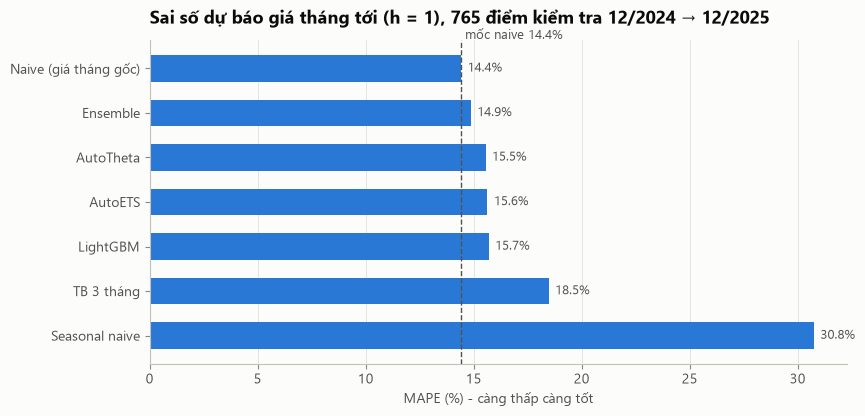

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.2))
names, vals = t1.index[::-1], t1["MAPE"].values[::-1] * 100
bars = ax.barh(names, vals, color=S1, height=0.6)
naive_v = t1.loc[MODELS["naive"], "MAPE"] * 100
ax.axvline(naive_v, color=INK2, linestyle="--", linewidth=1)
ax.text(naive_v, len(names) - 0.4, f" mốc naive {naive_v:.1f}%", color=INK2, fontsize=9, va="bottom")
for b, v in zip(bars, vals):
    ax.text(v + 0.3, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_xlabel("MAPE (%) - càng thấp càng tốt")
ax.grid(axis="y", visible=False)
ax.set_title(f"Sai số dự báo giá tháng tới (h = 1), {n1} điểm kiểm tra 12/2024 → 12/2025")
save(fig, "05_so_sanh_mo_hinh")

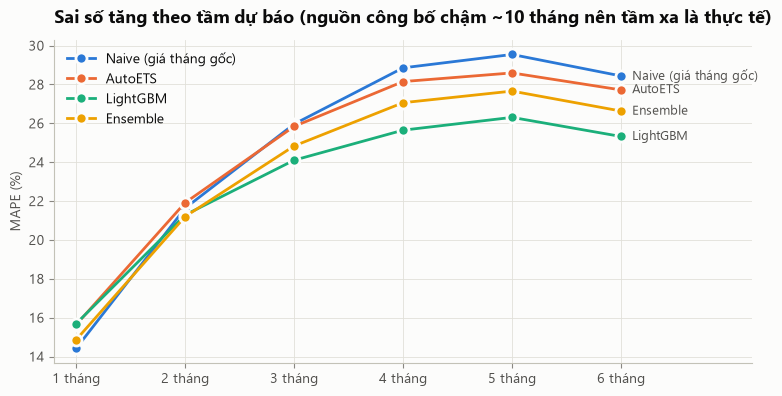

,Naive (giá tháng gốc),AutoETS,LightGBM,Ensemble
h,,,,
1,14.4%,15.6%,15.7%,14.9%
2,21.6%,21.9%,21.3%,21.2%
3,26.0%,25.8%,24.1%,24.8%
4,28.9%,28.1%,25.6%,27.1%
5,29.5%,28.6%,26.3%,27.7%
6,28.4%,27.7%,25.3%,26.6%


In [12]:
show = ["naive", "ets", "lgbm", "ensemble"]
by_h = pd.DataFrame({MODELS[m]: common.groupby("h")[f"ape_{m}"].mean() for m in show})
fig, ax = plt.subplots(figsize=(9, 4.2))
for m, c in zip(show, [S1, S2, S3, S4]):
    s = by_h[MODELS[m]] * 100
    ax.plot(s.index, s.values, color=c, marker="o", markersize=8, markeredgecolor=SURF, markeredgewidth=2,
            label=MODELS[m])
    ax.annotate(MODELS[m], (s.index[-1], s.values[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.set_xticks(range(1, H + 1), [f"{h} tháng" for h in range(1, H + 1)])
ax.set_ylabel("MAPE (%)")
ax.set_xlim(0.8, H + 1.2)
ax.legend(loc="upper left")
ax.set_title("Sai số tăng theo tầm dự báo (nguồn công bố chậm ~10 tháng nên tầm xa là thực tế)")
save(fig, "06_sai_so_theo_tam_du_bao")
by_h.style.format("{:.1%}")

In [13]:
by_cap = pd.DataFrame({MODELS[m]: common[common["h"] == 1].groupby("cap_gia", observed=True)[f"ape_{m}"].mean()
                       for m in show})
by_cap["số điểm"] = common[common["h"] == 1].groupby("cap_gia", observed=True).size()
by_cap.style.format({c: "{:.1%}" for c in by_cap.columns if c != "số điểm"})

,Naive (giá tháng gốc),AutoETS,LightGBM,Ensemble,số điểm
cap_gia,,,,,
Bán buôn,15.8%,14.3%,16.0%,15.0%,24
Bán lẻ,13.7%,15.5%,15.3%,14.4%,335
Thu mua,15.0%,15.8%,16.0%,15.3%,406


### Khoảng giá 80% (split conformal)
Sai số `log thật − log dự báo` trên **tập hiệu chỉnh** (gốc 12/2023 → 11/2024), lấy phân vị 10% và 90% theo
(cấp giá, h) → cộng vào dự báo trên **tập kiểm tra**. Khoảng tốt = độ phủ thực tế gần 80% và hẹp.

In [14]:
cal = res[res["origin"].isin(CAL_ORIGINS) & res["y_target"].notna()].copy()
cov_rows = []
for m in ("naive", "lgbm"):
    cal["err"] = cal["y_target"] - cal[m]
    q = cal.groupby(["cap_gia", "h"], observed=True)["err"].quantile([0.1, 0.9]).unstack()
    q.columns = ["q_lo", "q_hi"]
    tt = test.join(q, on=["cap_gia", "h"])
    lo, hi = tt[m] + tt["q_lo"], tt[m] + tt["q_hi"]
    tt["inside"] = (tt["y_target"] >= lo) & (tt["y_target"] <= hi)
    tt["width"] = np.exp(hi) / np.exp(tt[m]) - np.exp(lo) / np.exp(tt[m])
    res.loc[tt.index, f"{m}_lo"], res.loc[tt.index, f"{m}_hi"] = lo, hi
    for h, g in tt.groupby("h"):
        cov_rows.append({"phương pháp": f"{MODELS[m]} + conformal", "h": h, "độ phủ": g["inside"].mean(),
                         "độ rộng TB (% giá)": g["width"].mean()})
ets_t = test.dropna(subset=["ets_lo"])
ets_inside = (ets_t["y_target"] >= ets_t["ets_lo"]) & (ets_t["y_target"] <= ets_t["ets_hi"])
ets_w = np.exp(ets_t["ets_hi"]) / np.exp(ets_t["ets"]) - np.exp(ets_t["ets_lo"]) / np.exp(ets_t["ets"])
for h in range(1, H + 1):
    msk = ets_t["h"] == h
    cov_rows.append({"phương pháp": "AutoETS (khoảng sẵn có)", "h": h, "độ phủ": ets_inside[msk].mean(),
                     "độ rộng TB (% giá)": ets_w[msk].mean()})
cov = pd.DataFrame(cov_rows).pivot(index="h", columns="phương pháp")
cov.to_csv(OUT_DIR / "khoang_gia_80.csv", encoding="utf-8-sig")
cov.style.format("{:.0%}")

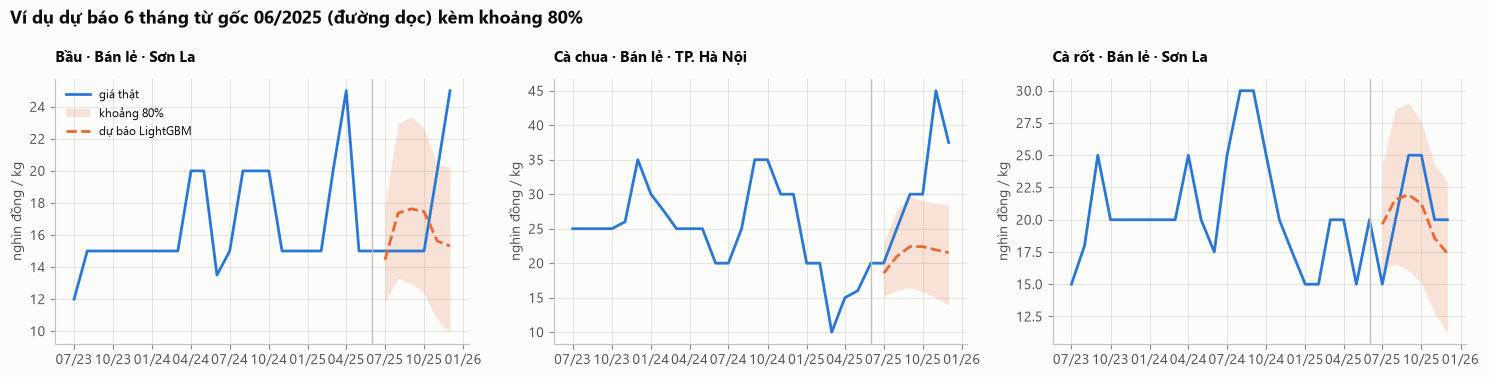

In [15]:
# ví dụ: 3 chuỗi dài, dự báo từ gốc 06/2025 với khoảng 80% (LightGBM + conformal)
O_EX = pd.Timestamp("2025-06-01")
ex_cand = res[(res["origin"] == O_EX) & res["lgbm_lo"].notna()].groupby("sid").size()
ex_cand = ex_cand[ex_cand == H].index
longest = lengths.loc[ex_cand].sort_values("count", ascending=False)
picks, seen = [], set()
for sid in longest.index:
    key = (meta.loc[sid, "san_pham"], meta.loc[sid, "cap_gia"])
    if key not in seen:
        picks.append(sid)
        seen.add(key)
    if len(picks) == 3:
        break
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, sid in zip(axes, picks):
    hist = grid[(grid["sid"] == sid) & (grid["month"] >= "2023-07-01")]
    fc = res[(res["sid"] == sid) & (res["origin"] == O_EX)].sort_values("target_month")
    ax.plot(hist["month"], np.exp(hist["y"]) / 1000, color=S1, label="giá thật")
    ax.fill_between(fc["target_month"], np.exp(fc["lgbm_lo"]) / 1000, np.exp(fc["lgbm_hi"]) / 1000,
                    color=S2, alpha=0.18, linewidth=0, label="khoảng 80%")
    ax.plot(fc["target_month"], np.exp(fc["lgbm"]) / 1000, color=S2, linestyle="--", label="dự báo LightGBM")
    ax.axvline(O_EX, color=AXIS, linewidth=1)
    r = meta.loc[sid]
    ax.set_title(f"{r['mat_hang']} · {r['loai_gia']} · {r['tinh_moi']}", fontsize=10.5)
    ax.set_ylabel("nghìn đồng / kg")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Ví dụ dự báo 6 tháng từ gốc 06/2025 (đường dọc) kèm khoảng 80%", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "07_vi_du_du_bao")

### Độ quan trọng feature (LightGBM, train trên toàn bộ dữ liệu đến 11/2025)

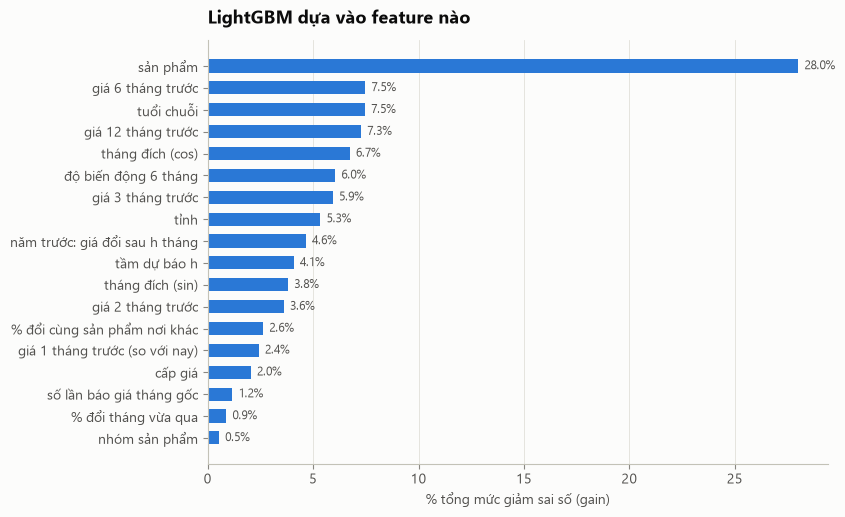

In [16]:
full_train = panel[panel["target"].notna()]
final = lgb.LGBMRegressor(**LGB_PARAMS, importance_type="gain").fit(full_train[FEATS], full_train["target"])
FEAT_VI = {"h": "tầm dự báo h", "d1": "giá 1 tháng trước (so với nay)", "d2": "giá 2 tháng trước",
           "d3": "giá 3 tháng trước", "d6": "giá 6 tháng trước", "d12": "giá 12 tháng trước",
           "ret1": "% đổi tháng vừa qua", "vol6": "độ biến động 6 tháng", "age": "tuổi chuỗi",
           "n_obs0": "số lần báo giá tháng gốc", "mkt_ret1": "% đổi cùng sản phẩm nơi khác",
           "season_h": "năm trước: giá đổi sau h tháng", "tm_sin": "tháng đích (sin)", "tm_cos": "tháng đích (cos)",
           "nhom_san_pham": "nhóm sản phẩm", "san_pham": "sản phẩm", "tinh_moi": "tỉnh", "cap_gia": "cấp giá"}
imp = pd.Series(final.feature_importances_, index=[FEAT_VI[f] for f in FEATS])
imp = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(imp.index, imp.values * 100, color=S1, height=0.6)
for i, v in enumerate(imp.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("% tổng mức giảm sai số (gain)")
ax.set_title("LightGBM dựa vào feature nào")
save(fig, "08_do_quan_trong_feature")

### Dự đoán chiều giá tháng tới (phân loại)
Nhãn: **tăng** (> +2%), **giảm** (< −2%), **đi ngang**. LGBMClassifier, cùng feature, rolling-origin trên 12 gốc kiểm tra.
Mốc so sánh: luôn đoán lớp phổ biến nhất trong dữ liệu train.

1780 điểm; phân bố thật: {'đi ngang': 0.361, 'tăng': 0.336, 'giảm': 0.303}


,accuracy,macro-F1
LGBMClassifier,47.6%,46.6%
Luôn đoán lớp phổ biến,36.1%,17.7%


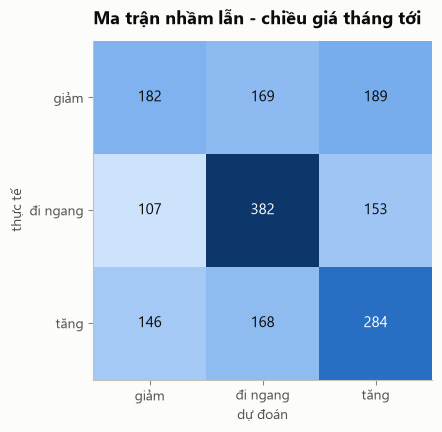

In [17]:
LABELS = ["giảm", "đi ngang", "tăng"]


def to_cls(r):
    return np.select([r > np.log1p(0.02), r < np.log1p(-0.02)], ["tăng", "giảm"], "đi ngang")


p1 = panel[panel["h"] == 1].copy()
p1["cls"] = np.where(p1["target"].notna(), to_cls(p1["target"]), None)
preds, truth, base = [], [], []
for o in TEST_ORIGINS:
    tr = p1[(p1["target_month"] <= o) & p1["cls"].notna()]
    te = p1[(p1["month"] == o) & p1["cls"].notna()]
    clf = lgb.LGBMClassifier(**{**LGB_PARAMS, "objective": "multiclass"}).fit(tr[FEATS], tr["cls"])
    preds += list(clf.predict(te[FEATS]))
    truth += list(te["cls"])
    base += [tr["cls"].mode()[0]] * len(te)
clf_tbl = pd.DataFrame({
    "accuracy": {"LGBMClassifier": np.mean(np.array(preds) == np.array(truth)),
                 "Luôn đoán lớp phổ biến": np.mean(np.array(base) == np.array(truth))},
    "macro-F1": {"LGBMClassifier": f1_score(truth, preds, average="macro"),
                 "Luôn đoán lớp phổ biến": f1_score(truth, base, average="macro")},
})
print(f"{len(truth)} điểm; phân bố thật:", pd.Series(truth).value_counts(normalize=True).round(3).to_dict())
display(clf_tbl.style.format("{:.1%}"))

cm = confusion_matrix(truth, preds, labels=LABELS)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=SEQ_BLUE)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() * 0.55 else INK)
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("dự đoán")
ax.set_ylabel("thực tế")
ax.set_title("Ma trận nhầm lẫn - chiều giá tháng tới")
save(fig, "09_ma_tran_nham_lan")

## 4. Phát hiện giá bất thường
Với mỗi chuỗi: robust z-score của % đổi giá so với tháng trước, `z = (r − median) / (1.4826 × MAD)`.
MAD có mức sàn = trung vị MAD của mọi chuỗi: chuỗi giữ giá cố định nhiều tháng có MAD ≈ 0, nếu không có sàn thì
một lần đổi giá bình thường cũng ra z rất lớn. Bất thường khi |z| > 4 **và** giá đổi > 30%.

In [18]:
an = df.dropna(subset=["ret1"]).copy()
med = an.groupby("sid")["ret1"].transform("median")
mad = an.groupby("sid")["ret1"].transform(lambda s: np.median(np.abs(s - s.median())))
mad_floor = an.groupby("sid")["ret1"].apply(lambda s: np.median(np.abs(s - s.median()))).replace(0, np.nan).median()
print(f"MAD sàn = {mad_floor:.3f} (≈ {np.expm1(mad_floor):.1%} thay đổi)")
an["z"] = (an["ret1"] - med) / (1.4826 * np.maximum(mad, mad_floor))
an["flag"] = (an["z"].abs() > 4) & (np.abs(np.expm1(an["ret1"])) > 0.3)
flags = an[an["flag"]].copy()
flags["% đổi"] = np.expm1(flags["ret1"])
print(f"{len(flags)} điểm bất thường / {len(an):,} lần đổi giá ({len(flags) / len(an):.1%}), "
      f"ở {flags['sid'].nunique()} chuỗi")
flag_tbl = flags.sort_values("z", key=np.abs, ascending=False)[
    ["month", "san_pham", "mat_hang", "tinh_moi", "loai_gia", "median_price", "% đổi", "z", "n_obs"]].head(12)
flags.to_csv(OUT_DIR / "gia_bat_thuong.csv", index=False, encoding="utf-8-sig")
flag_tbl.style.format({"% đổi": "{:+.0%}", "z": "{:+.1f}", "median_price": "{:,.0f}", "month": "{:%m/%Y}"})

MAD sàn = 0.091 (≈ 9.5% thay đổi)
91 điểm bất thường / 6,083 lần đổi giá (1.5%), ở 62 chuỗi


,month,san_pham,mat_hang,tinh_moi,loai_gia,median_price,% đổi,z,n_obs
6554,08/2025,Nhãn,Nhãn tiêu da bò,Vĩnh Long,Thu mua,"6,000",-74%,-10.0,5
5500,02/2025,Bắp cải,Bắp cải thảo,Sơn La,Bán lẻ,"5,000",-75%,-8.9,8
1107,05/2022,Nhãn,Nhãn,TP. Cần Thơ,Thu mua,"23,000",+229%,+8.8,7
1186,05/2022,Mướp,Mướp đắng,TP. Cần Thơ,Thu mua,"18,000",+200%,+8.2,6
6181,06/2025,Ổi,Ổi không hạt,Đồng Tháp,Thu mua,"3,000",-67%,-8.2,8
1020,03/2022,Mướp,Mướp đắng,TP. Cần Thơ,Thu mua,"6,000",-67%,-8.2,5
2062,10/2022,Mít,Mít thái,TP. Cần Thơ,Thu mua,"12,000",+200%,+8.2,3
197,06/2021,Xoài,Xoài Đài Loan,Sơn La,Bán lẻ,"10,000",-67%,-8.2,9
2493,01/2023,Vú sữa,Vú sữa lò rèn Cần Thơ,Đồng Tháp,Thu mua,"100,000",+292%,+7.9,3
6113,05/2025,Xoài,Xoài cát Hòa Lộc,An Giang,Thu mua,"16,000",-64%,-7.7,4


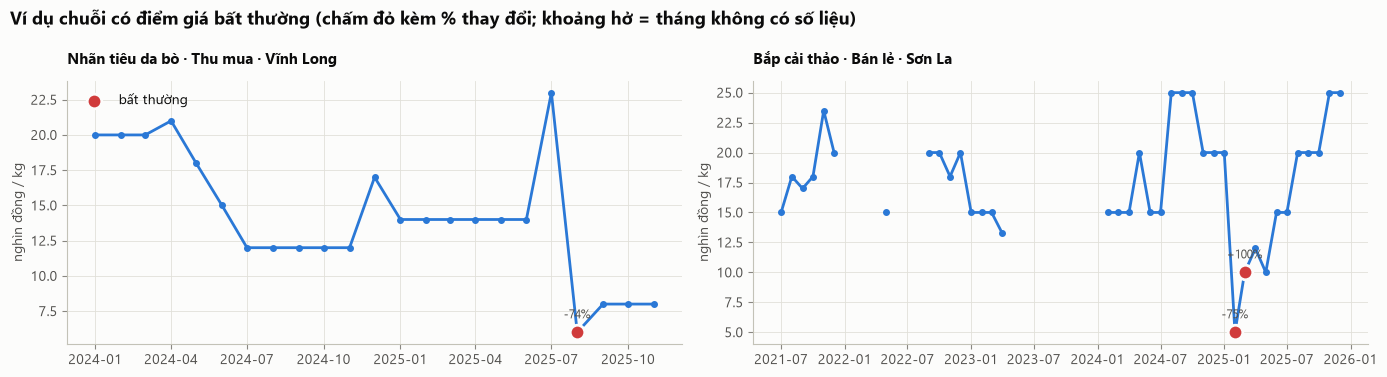

In [19]:
ex = flags.assign(az=flags["z"].abs()).sort_values("az", ascending=False).drop_duplicates("san_pham")["sid"].iloc[:2]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, sid in zip(axes, ex):
    s = grid[grid["sid"] == sid]                                    # lưới đủ tháng: tháng trống = khoảng hở
    f = flags[flags["sid"] == sid]
    ax.plot(s["month"], np.exp(s["y"]) / 1000, color=S1, marker="o", markersize=4)
    ax.scatter(f["month"], f["median_price"] / 1000, s=110, color=CRITICAL, zorder=3, edgecolor=SURF, linewidth=2,
               label="bất thường")
    for _, rr in f.iterrows():
        ax.annotate(f"{rr['% đổi']:+.0%}", (rr["month"], rr["median_price"] / 1000), xytext=(0, 10),
                    textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
    r = meta.loc[sid]
    ax.set_title(f"{r['mat_hang']} · {r['loai_gia']} · {r['tinh_moi']}", fontsize=10.5)
    ax.set_ylabel("nghìn đồng / kg")
axes[0].legend(loc="upper left")
fig.suptitle("Ví dụ chuỗi có điểm giá bất thường (chấm đỏ kèm % thay đổi; khoảng hở = tháng không có số liệu)",
             x=0.01, ha="left", fontsize=13,
             fontweight="bold")
fig.tight_layout()
save(fig, "10_gia_bat_thuong")

## 5. Chênh lệch giá bán lẻ - thu mua
Ở mức **sản phẩm** (gộp mọi tỉnh, vì giá lẻ đo ở miền Bắc còn giá thu mua đo ở miền Tây):
hệ số = trung vị giá bán lẻ / trung vị giá thu mua trong cùng tháng.

801 tháng-sản phẩm có cả 2 giá; 24 sản phẩm có ≥ 12 tháng


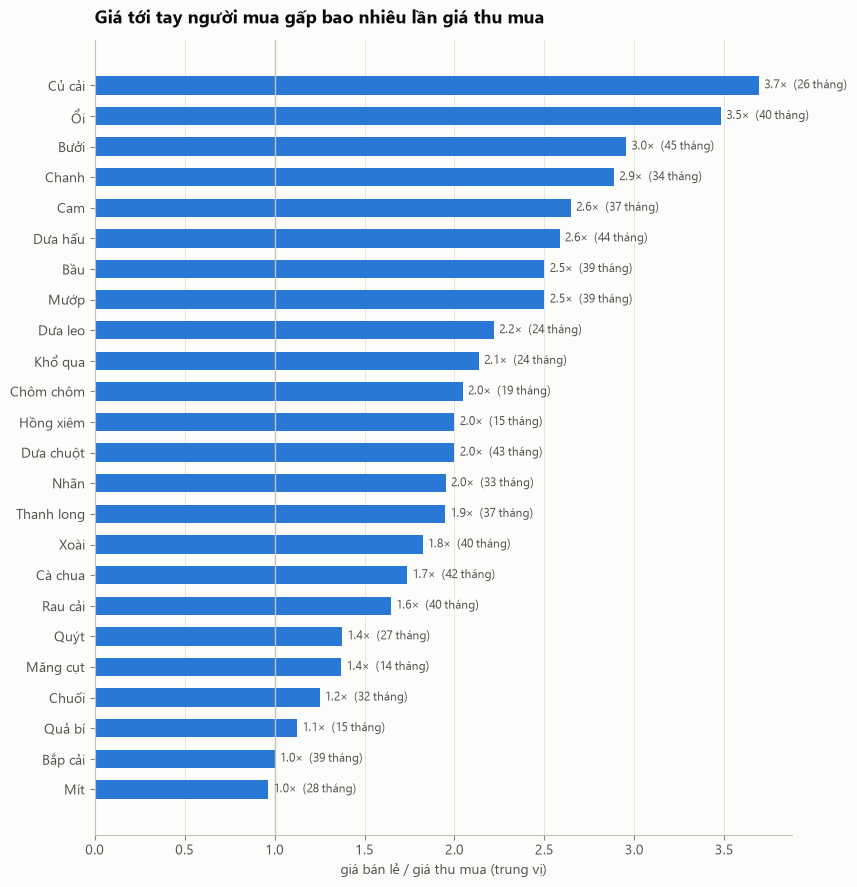

In [20]:
sp_m = df.groupby(["san_pham", "month", "cap_gia"])["median_price"].median().unstack()
both = sp_m.dropna(subset=["Bán lẻ", "Thu mua"]).copy()
both["he_so"] = both["Bán lẻ"] / both["Thu mua"]
spread = both.groupby("san_pham").agg(so_thang=("he_so", "size"), he_so_trung_vi=("he_so", "median"),
                                      gia_le=("Bán lẻ", "median"), gia_thu_mua=("Thu mua", "median"))
spread = spread[spread["so_thang"] >= 12].sort_values("he_so_trung_vi")
print(f"{len(both)} tháng-sản phẩm có cả 2 giá; {len(spread)} sản phẩm có ≥ 12 tháng")
spread.to_csv(OUT_DIR / "chenh_lech_le_thu_mua.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(9, 0.38 * len(spread) + 1.2))
ax.barh(spread.index, spread["he_so_trung_vi"], color=S1, height=0.6)
ax.axvline(1, color=AXIS, linewidth=1)
for i, (v, n) in enumerate(zip(spread["he_so_trung_vi"], spread["so_thang"])):
    ax.text(v + 0.03, i, f"{v:.1f}×  ({n} tháng)", va="center", fontsize=8.5, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("giá bán lẻ / giá thu mua (trung vị)")
ax.set_title("Giá tới tay người mua gấp bao nhiêu lần giá thu mua")
save(fig, "11_chenh_lech_le_thu_mua")

In [21]:
# độ trễ truyền dẫn: tương quan giữa % đổi giá thu mua ở tháng t−k và % đổi giá lẻ ở tháng t
lag_rows = []
for sp, g in both.reset_index().groupby("san_pham"):
    g = g.set_index("month").asfreq("MS")
    if g["he_so"].notna().sum() < 24:
        continue
    rl, rf = np.log(g["Bán lẻ"]).diff(), np.log(g["Thu mua"]).diff()
    for k in range(0, 4):
        pair = pd.concat([rl, rf.shift(k)], axis=1).dropna()
        if len(pair) >= 12:
            lag_rows.append({"san_pham": sp, "k": k, "corr": pair.corr().iloc[0, 1], "n": len(pair)})
lag = pd.DataFrame(lag_rows)
lag_sum = lag.groupby("k").agg(tuong_quan_tb=("corr", "mean"), so_san_pham=("san_pham", "nunique"))
print("Sản phẩm dùng để đo:", ", ".join(sorted(lag["san_pham"].unique())))
lag_sum.style.format({"tuong_quan_tb": "{:+.2f}"})

Sản phẩm dùng để đo: Bưởi, Bầu, Bắp cải, Cam, Chanh, Chuối, Cà chua, Củ cải, Dưa chuột, Dưa hấu, Dưa leo, Khổ qua, Mít, Mướp, Nhãn, Quýt, Rau cải, Thanh long, Xoài, Ổi


,tuong_quan_tb,so_san_pham
k,,
0,+0.05,20
1,+0.07,20
2,+0.01,20
3,-0.06,20


## Kết luận rút ra (số liệu ở các bảng phía trên; tổng hợp trong `KET_QUA.md`)